# AdaBoost with hyperparameter tuning with proper explanations

## Holiday Package Prediciton

### 1) Problem statement.
"Trips & Travel.Com" company wants to enable and establish a viable business model to expand the customer base.


One of the ways to expand the customer base -> introduce a new offering of packages. 
Currently, there are 5 types of packages the company is offering 
    Basic, 
    Standard, 
    Deluxe, 
    Super Deluxe, 
    King. 


Looking at the data of the last year:
    we observed that 18% of the customers purchased the packages. 
    However, the marketing cost was quite high because customers were contacted at random without looking at the available information.
    
The company is now planning to launch a new product i.e. Wellness Tourism Package. 

Wellness Tourism is defined as Travel that allows the traveler to maintain, enhance or kick-start a healthy lifestyle, and support or increase one's sense of well-being.

However, this time company wants to harness the available data of existing and potential customers to make the marketing expenditure more efficient.

### 2) Data Collection.
The Dataset is collected from https://www.kaggle.com/datasets/susant4learning/holiday-package-purchase-prediction
The data consists of 20 column and 4888 rows.

In [1]:
# the overall issue is :

# the stats is convey only 18% of the customers were purchased the packages by last year. this problem is basically happens due to wrong marketing strategy. 
# and the cause is marketing cost were high, the main reason is wrong strategy held like contacting customers by randomly instead of chosing the customer behavior or performance in a database, 
# so the company can't make a real customers or real package buyers. 
# and now, the company is plan to introduce a new package is based on the "wellness"
# so this package is completely based in the health and fitness and some other well-being activities.
# existing there is 5 packages such as Basic, Standard, Deluxe, Super Deluxe, King.


# so the statement is the trips and travel company want to create a viable business model to expand the real customers/buyers base though the new package campaign
# for this new campaign the company want to use exiting information to make the potential customers and also side by side they focus on marketing expenditure more efficient for this new campaign

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.model_selection import RandomizedSearchCV
warnings.filterwarnings("ignore")


###########

from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay, f1_score



%matplotlib inline

In [3]:
df = pd.read_csv("../Sources/Travel.csv")

In [3]:
df.head()

,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,200004,0,NaN,Self Enquiry,1,8.0,Small Business,Male,2,3.0,Basic,4.0,Divorced,1.0,0,5,1,0.0,Executive,18468.0


# EDA

In [4]:
# checking null values :
df.isnull().sum()

CustomerID                    0
ProdTaken                     0
Age                         226
TypeofContact                25
CityTier                      0
DurationOfPitch             251
Occupation                    0
Gender                        0
NumberOfPersonVisiting        0
NumberOfFollowups            45
ProductPitched                0
PreferredPropertyStar        26
MaritalStatus                 0
NumberOfTrips               140
Passport                      0
PitchSatisfactionScore        0
OwnCar                        0
NumberOfChildrenVisiting     66
Designation                   0
MonthlyIncome               233
dtype: int64

In [5]:
# now checking with percentages
null_pct = (df.isnull().mean() * 100).round(2)
print(null_pct[null_pct > 0])

null_pct.describe()

Age                         4.62
TypeofContact               0.51
DurationOfPitch             5.14
NumberOfFollowups           0.92
PreferredPropertyStar       0.53
NumberOfTrips               2.86
NumberOfChildrenVisiting    1.35
MonthlyIncome               4.77
dtype: float64


count    20.000000
mean      1.035000
std       1.784169
min       0.000000
25%       0.000000
50%       0.000000
75%       1.027500
max       5.140000
dtype: float64

In [6]:
# checking gender category
df['Gender'].value_counts() # in this "text error" appears, want to correct the female name

Gender
Male       2916
Female     1817
Fe Male     155
Name: count, dtype: int64

In [7]:
# checking MaritalStatus category
df['MaritalStatus'].value_counts() # in this "logic error", both of them are same single and unmarried, so i change to one category in unmarried 

MaritalStatus
Married      2340
Divorced      950
Single        916
Unmarried     682
Name: count, dtype: int64

In [8]:
# checking TypeofContact category
df['TypeofContact'].value_counts()

TypeofContact
Self Enquiry       3444
Company Invited    1419
Name: count, dtype: int64

In [9]:
# checking Occupation category
df['Occupation'].value_counts()

Occupation
Salaried          2368
Small Business    2084
Large Business     434
Free Lancer          2
Name: count, dtype: int64

In [10]:
# checking productpitched category
df['ProductPitched'].value_counts()

ProductPitched
Basic           1842
Deluxe          1732
Standard         742
Super Deluxe     342
King             230
Name: count, dtype: int64

In [11]:
# checking designation category
df['Designation'].value_counts()

Designation
Executive         1842
Manager           1732
Senior Manager     742
AVP                342
VP                 230
Name: count, dtype: int64

In [12]:
# checking the no.of trips of customers
df['NumberOfTrips'].value_counts()

NumberOfTrips
2.0     1464
3.0     1079
1.0      620
4.0      478
5.0      458
6.0      322
7.0      218
8.0      105
19.0       1
21.0       1
20.0       1
22.0       1
Name: count, dtype: int64

In [13]:
# these columns are almost same like have same information

# NumberOfChildrenVisiting & NumberOfPersonVisiting
# so i combine these two in single column

# Data Preprocessing

In [14]:
# backup the original data :

data_v1 = df.copy()

In [15]:
# fixing the text errors in features :

In [16]:
# 1. Gender

In [17]:
data_v1['Gender'] = df['Gender'].str.replace('Fe Male', 'Female')
data_v1['Gender'].value_counts()

Gender
Male      2916
Female    1972
Name: count, dtype: int64

In [18]:
# 2. MaritalStatus

In [19]:
data_v1['MaritalStatus'] = df['MaritalStatus'].str.replace('Single', 'Unmarried')

In [20]:
data_v1['MaritalStatus'].value_counts()

MaritalStatus
Married      2340
Unmarried    1598
Divorced      950
Name: count, dtype: int64

In [21]:
# filling missing values for numericals & categorical features:

In [22]:
# List of numerical column names
num_cols = df.select_dtypes(include='number').columns.tolist()
num_cols

['CustomerID',
 'ProdTaken',
 'Age',
 'CityTier',
 'DurationOfPitch',
 'NumberOfPersonVisiting',
 'NumberOfFollowups',
 'PreferredPropertyStar',
 'NumberOfTrips',
 'Passport',
 'PitchSatisfactionScore',
 'OwnCar',
 'NumberOfChildrenVisiting',
 'MonthlyIncome']

In [23]:
# checking with percent and filterout
num = df.select_dtypes(include='number').isnull().mean() * 100
print(num[num > 0])

Age                         4.623568
DurationOfPitch             5.135025
NumberOfFollowups           0.920622
PreferredPropertyStar       0.531915
NumberOfTrips               2.864157
NumberOfChildrenVisiting    1.350245
MonthlyIncome               4.766776
dtype: float64


In [24]:
# List of categorical (string/object) column names
cat_cols = df.select_dtypes(include='object').columns.tolist()
cat_cols

['TypeofContact',
 'Occupation',
 'Gender',
 'ProductPitched',
 'MaritalStatus',
 'Designation']

In [25]:
# checking with percent and filterout
num1 = df.select_dtypes(include='object').isnull().mean() * 100
print(num1[num1 > 0])

TypeofContact    0.511457
dtype: float64


In [26]:
# median imputation for numericals cols:
# mode imputation for categorical cols:

median_impute_cols = [
    'Age',
    'DurationOfPitch',
    'NumberOfFollowups',
    'PreferredPropertyStar',
    'NumberOfTrips',
    'NumberOfChildrenVisiting',
    'MonthlyIncome'
]

mode_impute_cols = [
    'TypeofContact'
]


fill_values = {}

for col in median_impute_cols:
    if col in data_v1.columns:
        fill_values[col] = data_v1[col].median()

for col in mode_impute_cols:
    if col in data_v1.columns:
        fill_values[col] = data_v1[col].mode()[0]

data_v1.fillna(value=fill_values, inplace = True)

In [27]:
data_v1.isnull().sum()

CustomerID                  0
ProdTaken                   0
Age                         0
TypeofContact               0
CityTier                    0
DurationOfPitch             0
Occupation                  0
Gender                      0
NumberOfPersonVisiting      0
NumberOfFollowups           0
ProductPitched              0
PreferredPropertyStar       0
MaritalStatus               0
NumberOfTrips               0
Passport                    0
PitchSatisfactionScore      0
OwnCar                      0
NumberOfChildrenVisiting    0
Designation                 0
MonthlyIncome               0
dtype: int64

In [28]:
data_v1.head()

,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Unmarried,1.0,1,2,1,0.0,Manager,20993.0
1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Unmarried,7.0,1,3,0,0.0,Executive,17090.0
3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,200004,0,36.0,Self Enquiry,1,8.0,Small Business,Male,2,3.0,Basic,4.0,Divorced,1.0,0,5,1,0.0,Executive,18468.0


In [29]:
# combining the NumberOfPersonVisiting and NumberOfChildrenVisiting

data_v1["TotalVisiting"] = data_v1['NumberOfPersonVisiting'] + data_v1["NumberOfChildrenVisiting"]

data_v1.drop(
    columns = ['NumberOfPersonVisiting', 'NumberOfChildrenVisiting'], inplace = True
)

In [30]:
data_v1.columns

Index(['CustomerID', 'ProdTaken', 'Age', 'TypeofContact', 'CityTier',
       'DurationOfPitch', 'Occupation', 'Gender', 'NumberOfFollowups',
       'ProductPitched', 'PreferredPropertyStar', 'MaritalStatus',
       'NumberOfTrips', 'Passport', 'PitchSatisfactionScore', 'OwnCar',
       'Designation', 'MonthlyIncome', 'TotalVisiting'],
      dtype='object')

# Model Training with samples algorithms to understand the flow

In [31]:
X = data_v1.drop('ProdTaken', axis = 1)
y = data_v1[['ProdTaken']]

In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y,
    test_size = 0.2,
    random_state = 42
)

In [33]:
X_train.shape, X_test.shape

((3910, 18), (978, 18))

In [34]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4888 entries, 0 to 4887
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   CustomerID              4888 non-null   int64  
 1   Age                     4888 non-null   float64
 2   TypeofContact           4888 non-null   object 
 3   CityTier                4888 non-null   int64  
 4   DurationOfPitch         4888 non-null   float64
 5   Occupation              4888 non-null   object 
 6   Gender                  4888 non-null   object 
 7   NumberOfFollowups       4888 non-null   float64
 8   ProductPitched          4888 non-null   object 
 9   PreferredPropertyStar   4888 non-null   float64
 10  MaritalStatus           4888 non-null   object 
 11  NumberOfTrips           4888 non-null   float64
 12  Passport                4888 non-null   int64  
 13  PitchSatisfactionScore  4888 non-null   int64  
 14  OwnCar                  4888 non-null   

In [35]:
# Changing the Categorical features into numerical for model understanding

# 'TypeofContact'
#  'Occupation'
#  'Gender'
#  'ProductPitched'
#  'MaritalStatus'
#  'Designation'

# scaling the numerical columns for equal mean and variance for all numerical features like (-2 to +2 range)

# these two transforms were done after spliting the training dataset cause of data leakage. 

In [36]:
cat_features = X.select_dtypes(include = 'object').columns
num_features = X.select_dtypes(exclude = 'object').columns

# drop='first'         -->  this is to avoid the mirror issues.
# sparse_output=False  -->  encoder compress the format the output , 
# so the pandas can't read and retrive it 
# so the this helps the return it in a default in grid format ,
# so the pandas can easily understand it and able to retrieve it.

cat_transformer = OneHotEncoder(drop='first', sparse_output=False)
numeric_transformer = StandardScaler()

preprocessor = ColumnTransformer(
    [
        ("OneHotEncoder", cat_transformer, cat_features),
        ("StandardScaler", numeric_transformer, num_features)
    ],
    remainder='passthrough'
)

preprocessor.set_output(transform="pandas")

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('OneHotEncoder', ...), ('StandardScaler', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer

In [37]:
data_v1.columns

Index(['CustomerID', 'ProdTaken', 'Age', 'TypeofContact', 'CityTier',
       'DurationOfPitch', 'Occupation', 'Gender', 'NumberOfFollowups',
       'ProductPitched', 'PreferredPropertyStar', 'MaritalStatus',
       'NumberOfTrips', 'Passport', 'PitchSatisfactionScore', 'OwnCar',
       'Designation', 'MonthlyIncome', 'TotalVisiting'],
      dtype='object')

In [38]:
X_train = preprocessor.fit_transform(X_train) # this is for model learning 
# to see the parameter like mean and standard deviation for all columns(features) and model will learn this completely.


X_test = preprocessor.transform(X_test)# this is testing data with same training data's parameter to avoid the data leakages, and importantly model prediction would be broken if we use the diff preprocessing settings,
# want to use the same settings for both training and testing to maintain the consistent.
# in this by using the transform alone it will take the parameters from the training data.
# the reason behind the transform for testing data : the model have learn from that settings , suddendly we take the testing data into fit like mean and S.D means and pass it with this means 
# the model will get confused and doesn't make sense of model predictions
# so the rule is , in which settings the model is learned on that exact settings only the new data want to come inside to get the model's best predictions 

In [39]:
pd.DataFrame(X_train)

,OneHotEncoder__TypeofContact_Self Enquiry,OneHotEncoder__Occupation_Large Business,OneHotEncoder__Occupation_Salaried,OneHotEncoder__Occupation_Small Business,OneHotEncoder__Gender_Male,OneHotEncoder__ProductPitched_Deluxe,OneHotEncoder__ProductPitched_King,OneHotEncoder__ProductPitched_Standard,OneHotEncoder__ProductPitched_Super Deluxe,OneHotEncoder__MaritalStatus_Married,...,StandardScaler__CityTier,StandardScaler__DurationOfPitch,StandardScaler__NumberOfFollowups,StandardScaler__PreferredPropertyStar,StandardScaler__NumberOfTrips,StandardScaler__Passport,StandardScaler__PitchSatisfactionScore,StandardScaler__OwnCar,StandardScaler__MonthlyIncome,StandardScaler__TotalVisiting
3995,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,...,-0.721400,-1.020350,1.284279,-0.725271,-0.127737,-0.632399,0.679690,0.782966,-0.382245,-0.774151
2610,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,-0.721400,0.690023,0.282777,-0.725271,1.511598,-0.632399,0.679690,0.782966,-0.459799,0.643615
3083,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.721400,-1.020350,0.282777,1.771041,0.418708,-0.632399,0.679690,0.782966,-0.245196,-0.065268
3973,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,...,-0.721400,-1.020350,1.284279,-0.725271,-0.127737,-0.632399,1.408395,-1.277194,0.213475,-0.065268
4044,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.721400,2.400396,-1.720227,-0.725271,1.511598,-0.632399,-0.049015,-1.277194,-0.024889,2.061382
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4426,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,...,-0.721400,-0.653841,1.284279,-0.725271,-0.674182,-0.632399,-1.506426,0.782966,-0.536973,0.643615
466,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.455047,-0.898180,-0.718725,1.771041,-1.220627,-0.632399,1.408395,0.782966,1.529609,-0.065268
3092,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.455047,1.545210,0.282777,-0.725271,2.058043,-0.632399,-0.777720,0.782966,-0.360576,0.643615
3772,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,...,1.455047,1.789549,1.284279,-0.725271,-0.127737,-0.632399,-1.506426,0.782966,-0.252799,0.643615


In [40]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3910 entries, 3995 to 860
Data columns (total 27 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   OneHotEncoder__TypeofContact_Self Enquiry   3910 non-null   float64
 1   OneHotEncoder__Occupation_Large Business    3910 non-null   float64
 2   OneHotEncoder__Occupation_Salaried          3910 non-null   float64
 3   OneHotEncoder__Occupation_Small Business    3910 non-null   float64
 4   OneHotEncoder__Gender_Male                  3910 non-null   float64
 5   OneHotEncoder__ProductPitched_Deluxe        3910 non-null   float64
 6   OneHotEncoder__ProductPitched_King          3910 non-null   float64
 7   OneHotEncoder__ProductPitched_Standard      3910 non-null   float64
 8   OneHotEncoder__ProductPitched_Super Deluxe  3910 non-null   float64
 9   OneHotEncoder__MaritalStatus_Married        3910 non-null   float64
 10  OneHotEncoder__

In [41]:
models = {
    "Adaboost" : AdaBoostClassifier(),
    "Random forest" : RandomForestClassifier()
}

In [42]:
for mdl in models:
    model = models[mdl]
    model.fit(X_train, y_train)

    # predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    ## metrics :

    # accuracy
    model_train_accuracy = accuracy_score(y_train, y_train_pred)
    model_test_accuracy = accuracy_score(y_test, y_test_pred)
    # precision score
    model_train_precision = precision_score(y_train, y_train_pred)
    model_test_precision = precision_score(y_test, y_test_pred)
    # recall
    model_train_recall = recall_score(y_train, y_train_pred)
    model_test_recall = recall_score(y_test, y_test_pred)


    print(f"//{mdl}//")

    print("Model performance")
    print(f"Accuracy:  Training {model_train_accuracy} VS Testing {model_test_accuracy}")
    print(f"precision: Training {model_test_precision} VS Testing {model_test_precision}")
    print(f"recall:    Training {model_test_recall}    VS Testing {model_test_recall} \n")

//Adaboost//
Model performance
Accuracy:  Training 0.8501278772378517 VS Testing 0.8353783231083844
precision: Training 0.7142857142857143 VS Testing 0.7142857142857143
recall:    Training 0.2617801047120419    VS Testing 0.2617801047120419 

//Random forest//
Model performance
Accuracy:  Training 1.0 VS Testing 0.9151329243353783
precision: Training 0.9285714285714286 VS Testing 0.9285714285714286
recall:    Training 0.612565445026178    VS Testing 0.612565445026178 



# Adaboost with hyperparameter tuning

# n_estimator :

this is the number of weak learners to set inside the ada boost algorithm

estimator = small:

-> Faster

-> may underfit due to low number of weak learners

-> less complex due to model doesn't learn that much

estimator = large:

-> slow training 

-> better learning 

-> can overfit due to high number of weak learners 

-> like may learn all edges and noise by high volume weak leaners 

# learning_rate :

controls how much each weak learners contributes to final prediction

Learning rate = 1.0: Each learner has a stronger influence.

Learning rate = 0.1: Each learner has a smaller influence.

100 estimators: The number of learners trained.

learning rate = small:

-> slow leaning due to small learning rate with high estimator can get time to learn

-> more stable , which means each model small learning rate but have a strong understand due to small learning rate

learning rate = large:

-> may get overfit , due to high learning with low estimator , which means each model have high influence to the final model which may get overfit

conclude : -> A lower learning rate means each learner contributes less, 
so you may need more learners to achieve good results.

# Estimator

estimator are which model we are going to use as weak learner

why ? decision tree / decision stump :

$$ weak learners - we need weak learner , that is to satisfy the architecture of AdaBoost

$$ AdaBoost is designed for weak learner -> sequentially -> imporve weak learners

$$ Decision Stump(DT = depth 1) -> getting weak learner -> simple -> fast -> gradually improves

$$ learns simple rules like yes/no in decision tree.


what if LR ?

can we use ? yes but 
-> Logistic Reg is already a strong learner, which means its already using inbuid math like sigmoid function to 
calculate each data point and check the error and draws a boundary thresold to decide 0 or 1 and internally 
there are so much math are there, so this make the architecture too complex and slow and mainly defeats 
the purpose of boosting and often leads to overfitting.

what if SVC ?

-> Too Smart: SVC is naturally a strong learner designed to find the absolute widest, most optimal boundary for the whole dataset.

-> Ignores Weights: It only focuses on points closest to its boundary (Support Vectors), 
making it heavily resist shifting to fix AdaBoost's weighted mistakes.

-> Too Slow: SVC relies on heavy matrix math, making it computationally exhausting to train 100 of them sequentially.

-> Defeats Boosting: Using such a rigid, complex model defeats the purpose of boosting and quickly leads to massive overfitting.


what if Random Forest ?

-> it is already a massive team of trees, not a single player.

-> Already a Strong Ensemble: Random Forest is already a collection of 100+ deep decision trees, 
making it a highly accurate, strong learner right out of the box.

-> Violates the "Weak Learner" Rule: AdaBoost is specifically designed to combine tiny, 
weak models (1-split stumps); adding an entire forest inside each step breaks the algorithm's core logic.

-> Insanely Slow: Training 100 Random Forests sequentially means building roughly 10,000 deep trees, 
which would freeze your computer and destroy processing speed.

-> Guaranteed Overfitting: Combining a complex ensemble inside another boosting ensemble creates an overly complicated model 
that will instantly memorize the training data and fail on new data, which cause overfitting .




in this adaboost the decision tree is a default and perfect choice. other that svm, logistic regression.

$$ Perfect for "Weak Learners": AdaBoost relies on a team of "weak learners"—models 
that are only slightly better than a random guess. A single decision stump fits this description perfectly.

$$ Speed: AdaBoost builds 100+ estimators sequentially (one after the other). 
Training 100 SVMs or Random Forests would be incredibly slow, whereas training 100 decision stumps takes less than a second.

$$ Sensitivity to Data Weights: AdaBoost works by changing the "weights" (importance) of data points after every step.
Decision trees adapt to these weight changes instantly and easily. 
Models like SVM or Logistic Regression are mathematically harder and slower to tweak with weights

# Algorithm

1. SAMME - old
Staged Additive Modeling using a Multi-class Exponential loss function

2. SAMME - updated one
SAMME with real-valued predictions


-> SAMME is the exact mathematical engine that runs the adaboost classification architecture.
this is the one the whole work flow of what the adaboost defines in the notes.

-> this will handle the error management and the next learner importance like weightage and finally do the voting happens.

-> in this AdaBoost is like a general blue print like sequential learners and changing the weight and passing to the next weak learner

-> SAMME is the specific formula inside the blue print that handle the math for the classification problems 
like categories.



Working of SAMME :

eg : this is a single tree that what the SAMME do

Actual:
dog, cat, dog

pred:
dog, cat, cat -> 2 correct , 1 wrong

accuracy: 0.666
2/3

final update the weight :
increase weight of wrong samples



Working of SAMME.R :

smarter than SAMME
-> this SAMME.R uses prediction probability


Actual:
dog, cat, dog

pred:
dog - 90%
cat - 50%
cat - 60%|

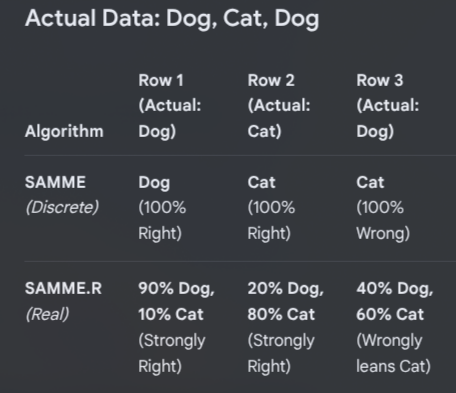

In [19]:
from IPython.display import Image, display
img = "../../My notes/Algorithms - SAMME,SAMME.R.png"
display(Image(filename = img, width = 300))

In [89]:
# setting the parameters for two different models :
# Random Forest
# AdaBoost

rf_params = {
    "max_depth" : [5,8,15,None,10],
    "max_features" : [5,7,"auto", 8],
    "min_samples_split" : [2,8,20,15],
    "n_estimators" : [100,200,500,1000]
}

adaboost_params = {
    "n_estimators" : [50,60,70,80,90],
    "learning_rate" : [0.01,0.1,1.0]
}

In [80]:
randomcv_models = [
    ("RF", RandomForestClassifier(), rf_params),
    ("AdaBoost", AdaBoostClassifier(), adaboost_params)
]

In [81]:
randomcv_models

[('RF',
  RandomForestClassifier(),
  {'max_depth': [5, 8, 15, None, 10],
   'max_features': [5, 7, 'auto', 8],
   'min_samples_split': [2, 8, 20, 15],
   'n_estimators': [100, 200, 500, 1000]}),
 ('AdaBoost',
  AdaBoostClassifier(),
  {'n_estimators': [50, 60, 70, 80, 90], 'learning_rate': [0.01, 0.1, 1.0]})]

In [91]:
# lopping the hyperparamter with two models with distribution of parameter
# and this find the best parameter for each model to get the best results

model_param = {}

for name,model,params in randomcv_models:
    random = RandomizedSearchCV(
        estimator = model,
        param_distributions = params,
        n_iter = 100,
        cv = 3,
        verbose = 2,
        n_jobs = -1
    )
    random.fit(X_train, y_train)
    model_param[name] = random.best_params_


for model_name in model_param:
    print(model_param[model_name])

Fitting 3 folds for each of 100 candidates, totalling 300 fits
Fitting 3 folds for each of 15 candidates, totalling 45 fits
{'n_estimators': 100, 'min_samples_split': 2, 'max_features': 8, 'max_depth': 15}
{'n_estimators': 80, 'learning_rate': 1.0}


# Train again with best parameter

In [92]:
# train with the best params in two models

models = {
    "Random_forest" : RandomForestClassifier(
        n_estimators = 200, 
        min_samples_split= 2, 
        max_features= 7, 
        max_depth=  None
    ),

    "AdaBoost" : AdaBoostClassifier(
        n_estimators=  80, 
        learning_rate= 1.0
    )
}

In [93]:
# train and prediction
# evaluating the metrics with training and testing rate to find the overfit or underfit


for mdl in models:
    model = models[mdl]
    model.fit(X_train, y_train)

    # predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    ## metrics :

    # accuracy
    model_train_accuracy = accuracy_score(y_train, y_train_pred)
    model_test_accuracy = accuracy_score(y_test, y_test_pred)
    # precision score
    model_train_precision = precision_score(y_train, y_train_pred)
    model_test_precision = precision_score(y_test, y_test_pred)
    # recall
    model_train_recall = recall_score(y_train, y_train_pred)
    model_test_recall = recall_score(y_test, y_test_pred)


    print(f"//{mdl}//")

    print("Model performance")
    print(f"Accuracy:  Training {model_train_accuracy} VS Testing {model_test_accuracy}")
    print(f"precision: Training {model_test_precision} VS Testing {model_test_precision}")
    print(f"recall:    Training {model_test_recall}    VS Testing {model_test_recall} \n")

//Random_forest//
Model performance
Accuracy:  Training 1.0 VS Testing 0.9233128834355828
precision: Training 0.9461538461538461 VS Testing 0.9461538461538461
recall:    Training 0.643979057591623    VS Testing 0.643979057591623 

//AdaBoost//
Model performance
Accuracy:  Training 0.8537084398976982 VS Testing 0.843558282208589
precision: Training 0.796875 VS Testing 0.796875
recall:    Training 0.2670157068062827    VS Testing 0.2670157068062827 

[CV] END max_depth=5, max_features=auto, min_samples_split=20, n_estimators=200; total time=   0.0s
[CV] END max_depth=10, max_features=auto, min_samples_split=15, n_estimators=500; total time=   0.0s
[CV] END max_depth=10, max_features=5, min_samples_split=20, n_estimators=500; total time=   1.7s
[CV] END max_depth=10, max_features=8, min_samples_split=2, n_estimators=100; total time=   0.4s
[CV] END max_depth=15, max_features=8, min_samples_split=2, n_estimators=1000; total time=   5.8s
[CV] END max_depth=15, max_features=8, min_samples_sp